# 01 - Common Voice Albanian: dataset exploration

**Phase 1: Dataset Collection & Analysis.** Our thesis asks whether a model can distinguish real human Albanian speech from AI-generated Albanian speech. This notebook describes the available human-speech metadata before any sentence selection, synthesis, splitting, or training.

The hybrid workflow keeps parsing and audit logic in [`scripts/audit_common_voice.py`](../scripts/audit_common_voice.py), its tests in [`tests/test_audit_common_voice.py`](../tests/test_audit_common_voice.py), and evidence in [`reports/common_voice_27_sq_metadata_audit.json`](../reports/common_voice_27_sq_metadata_audit.json). The notebook reuses those results, checks them against current inputs, and explains their research implications. No audio is opened or saved.

## Provenance and scope

The bundled dataset [README](../data/raw/common_voice_27_sq/README.md) identifies **Mozilla Common Voice Scripted Speech 27.0, Albanian (`sq`), `cv-corpus-27.0-2026-09-11`**. It declares CC0 and asks users not to determine speakers' identities. These provenance statements come from the local README, not an independent remote verification.

The README describes 6,553 recordings, including 6,374 validated recordings. Sentence-corpus rows describe prompts and must not be counted as additional audio clips. Supplied train/dev/test manifests are subsets of the validated collection, not extra recordings. Here, "official splits" means those supplied release manifests, not splits created for this thesis.

**Reproduce:** open from the repository root or `notebooks/`, select the project `.venv313` kernel, restart, and run all cells in order. Python 3.13, a Jupyter kernel and Matplotlib are required; the relevant versions are recorded in the existing `requirements.txt`. Nothing is installed by this notebook. The first code cell reports the actual interpreter, Python version, Matplotlib version and whether the project environment is in use. Saved outputs must be checked there rather than assuming the selected kernel from its display name.

**Verified execution (2026-11-05):** all eleven nonempty code cells ran successfully in `.venv313` with Python 3.13.7 and Matplotlib 3.10.7. The saved first-cell output identifies the actual interpreter.


In [1]:
from pathlib import Path
import sys
import json
import math
import platform
import statistics

sys.dont_write_bytecode = True  # Avoid creating cache files when importing project code.
# Support the two documented starting locations: repository root or notebooks/.
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / 'scripts/audit_common_voice.py').is_file():
    raise RuntimeError('Open this notebook from the repository root or notebooks/.')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from scripts.audit_common_voice import audit, discover_root, read_tsv, sha256
from IPython.display import display, Markdown

DATA_BASE = PROJECT_ROOT / 'data/raw/common_voice_27_sq'
AUDIT_PATH = PROJECT_ROOT / 'reports/common_voice_27_sq_metadata_audit.json'
preferred_python = PROJECT_ROOT / '.venv313/Scripts/python.exe'
print('Interpreter:', sys.executable)
print('Runtime Python:', platform.python_version())
print('Using .venv313:', Path(sys.executable).resolve() == preferred_python.resolve())

import matplotlib
import matplotlib.pyplot as plt

print('Matplotlib:', matplotlib.__version__)

Interpreter: <PROJECT_ROOT>/.venv313/Scripts/python.exe
Runtime Python: 3.13.7
Using .venv313: True


Matplotlib: 3.10.7


## Verification before exploration

The saved JSON is the reference audit. `audit()` discovers the nested dataset root, applies its existing TSV-specific parser policy, checks row widths, and hashes every TSV before and after reading. We compare the new result to the saved result, ignoring only the two Python runtime descriptors. A mismatch stops this notebook rather than silently replacing the evidence. SHA-256 computes a 64-character fingerprint of a file's bytes. Matching fingerprints provide a reproducible check that inputs have not changed; they do not establish the download's authenticity. An `assert` checks a condition and stops execution if it is false. Here assertions prevent continuing with changed inputs or inconsistent counts; run normally, without Python's `-O` option, which disables assertions.

Only compact aggregate tables and figures are displayed. Raw rows, sentence lists, audio, and hashed speaker identifiers remain out of cell outputs. The full audit is held in memory, not displayed wholesale.

In [2]:
saved_audit = json.loads(AUDIT_PATH.read_text(encoding='utf-8-sig'))
current_audit = audit(DATA_BASE)
# Compare every audit field except the Python runtime used to produce it.
assert current_audit.keys() == saved_audit.keys(), 'Audit report fields have changed.'
for key in current_audit:
    if key in ('python_version', 'python_build'):
        continue
    assert current_audit[key] == saved_audit[key], f'Audit mismatch: {key}. Stop and review.'

DATASET_ROOT = discover_root(DATA_BASE)
metadata = current_audit['files']
print('Dataset root:', DATASET_ROOT.relative_to(PROJECT_ROOT).as_posix())
print('Reference:', AUDIT_PATH.relative_to(PROJECT_ROOT).as_posix())
print('Reference JSON SHA-256:', sha256(AUDIT_PATH))
print('Audit module SHA-256:', sha256(PROJECT_ROOT / 'scripts/audit_common_voice.py'))
print('Reference Python:', saved_audit['python_version'])
print('Verified:', len(metadata), 'TSV hashes and all non-runtime audit results match.')
hash_table = '| Input TSV | SHA-256 |\n|---|---|\n'
for name, info in metadata.items():
    hash_table += f"| {name} | `{info['sha256']}` |\n"
display(Markdown(hash_table))

Dataset root: data/raw/common_voice_27_sq
Reference: reports/common_voice_27_sq_metadata_audit.json
Reference JSON SHA-256: 94c191287838dccef5d86bd0c58e7acdd480713d3cf209ff71680cf92ceada50
Audit module SHA-256: d98c24af605d540e355e00be120f146d2ca7ae57f04f94d262d92240d78e525e
Reference Python: 3.13.7
Verified: 10 TSV hashes and all non-runtime audit results match.


| Input TSV | SHA-256 |
|---|---|
| clip_durations.tsv | `0b1cfd83aaf255543b9a8e46ca2014e23e0d46438ffde91c4e30b934399fa3e6` |
| dev.tsv | `918867163db6da736ab3c3e7352d7437e0d002dbfafc071364c0aaeae1076220` |
| invalidated.tsv | `3bf9745842137a7c927bca28ea30ea014d99a57cb886bc832c7764c68fbd540b` |
| other.tsv | `b2f45a6b90894bca30eefc89360a816e7abf4275f751e3394a8cdcf68cad5441` |
| reported.tsv | `9b57958400090c28a1a62925c436b112cf541ddfb82a04b2cf373b00baac62ff` |
| test.tsv | `f4c68b7509aecfc5e7b5e7d45a728e10ed79f1bc0c91aa2ad91ad74cb905f807` |
| train.tsv | `05a2e0778f007d8e299c5304fe5cdfc2d01b135380c1d40e5ca4198e42c3dd2c` |
| unvalidated_sentences.tsv | `3bcea799a1685494eb5693b56c7b67744d9f334964e9140eca4f27e3639015c3` |
| validated.tsv | `fdb687c7d2e1b81cb7e00646fb11aa22e968dbfc7dd89c4ed06886d423b43373` |
| validated_sentences.tsv | `c65a873715e4123844b8c71ba282e73f2b77f29731110d340ba6da648825b64c` |


## Parsing caveat: why 6,374 and 6,344 both appeared

**Measured on the available bytes:** the clip manifests require literal quotation marks (`csv.QUOTE_NONE`). The sentence-corpus and report tables use CSV quote handling (`csv.QUOTE_MINIMAL`). Both policies are implemented in the existing module; we do not replace them with a blanket pandas/CSV default.

With default quote-aware parsing, physical lines 4,205-4,235 of `validated.tsv` become one multiline record. That consumes 31 physical rows as one, reducing the result by 30: 6,374 becomes 6,344. The diagnostic below is reused from the audit, not reimplemented here. The available evidence explains the discrepancy on the current file; without an earlier file hash, historical byte identity is unproven. Parser settings for all inputs are preserved in the reference JSON.

In [3]:
diagnostic = current_audit['validated_quote_diagnostic']
assert diagnostic['reproduces_reported_6374_vs_6344']
print('Correct literal-quote count:', diagnostic['literal_quote_rows'])
print('Diagnostic quote-aware count:', diagnostic['rows'])
print('Merged physical-line spans:', diagnostic['multiline_record_spans'])
print('Validated parser:', metadata['validated.tsv']['parser'])
print('Sentence-corpus parser:', metadata['validated_sentences.tsv']['parser']['quoting'])

Correct literal-quote count: 6374
Diagnostic quote-aware count: 6344
Merged physical-line spans: [{'first_line': 4205, 'last_line': 4235, 'physical_lines': 31}]
Validated parser: {'encoding': 'utf-8-sig', 'newline': '', 'delimiter': '\t', 'quoting': 'csv.QUOTE_NONE', 'quotechar': '"', 'doublequote': True, 'escapechar': None, 'strict': True, 'skipinitialspace': False}
Sentence-corpus parser: csv.QUOTE_MINIMAL


## Verified counts and supplied split sizes

**Measured:** counts below come from the fresh audit after comparison with the saved JSON. A speaker count means unique nonempty `client_id` values, not independently verified people. Text counts here use exact raw string equality. Missing values mean empty or whitespace-only fields.

The chart compares supplied split sizes. It does not imply the splits are balanced or suitable for the thesis. Ten validated clips are outside their union, as checked below using metadata paths without reading audio.

In [4]:
manifest_names = ['validated.tsv', 'train.tsv', 'dev.tsv', 'test.tsv', 'invalidated.tsv', 'other.tsv']
table = '| Manifest | Rows | Unique paths | Speaker IDs | Exact texts |\n|---|---:|---:|---:|---:|\n'
for name in manifest_names:
    info = metadata[name]
    unique = info['unique_nonempty']
    table += f"| {name} | {info['rows']:,} | {unique['path']:,} | {unique['client_id']:,} | {unique['sentence']:,} |\n"
display(Markdown(table))
assert metadata['validated.tsv']['rows'] == 6374
assert metadata['validated.tsv']['unique_nonempty']['path'] == 6374
assert metadata['validated.tsv']['unique_nonempty']['client_id'] == 147
split_names = ['train.tsv', 'dev.tsv', 'test.tsv']
manifest_paths = {}
for name in ['validated.tsv', *split_names]:
    _, rows = read_tsv(DATASET_ROOT / name)
    manifest_paths[name] = {row['path'] for row in rows}
split_union = set()
for name in split_names:
    split_union.update(manifest_paths[name])
assert split_union <= manifest_paths['validated.tsv']
print('Validated clips outside supplied splits:', len(manifest_paths['validated.tsv'] - split_union))

| Manifest | Rows | Unique paths | Speaker IDs | Exact texts |
|---|---:|---:|---:|---:|
| validated.tsv | 6,374 | 6,374 | 147 | 6,364 |
| train.tsv | 2,658 | 2,658 | 2 | 2,658 |
| dev.tsv | 1,795 | 1,795 | 7 | 1,795 |
| test.tsv | 1,911 | 1,911 | 138 | 1,911 |
| invalidated.tsv | 179 | 179 | 45 | 179 |
| other.tsv | 0 | 0 | 0 | 0 |


Validated clips outside supplied splits:

 10


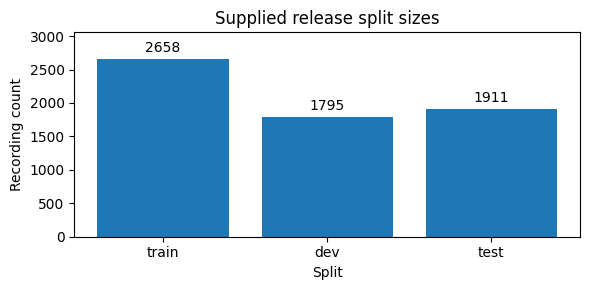

In [5]:
split_labels = [name.removesuffix('.tsv') for name in split_names]
split_sizes = [metadata[name]['rows'] for name in split_names]

fig, ax = plt.subplots(figsize=(6, 3))
bars = ax.bar(split_labels, split_sizes, color='tab:blue')
ax.bar_label(bars, padding=3)
ax.set(title='Supplied release split sizes', xlabel='Split', ylabel='Recording count')
ax.set_ylim(0, max(split_sizes) * 1.15)
fig.tight_layout()
plt.show()
plt.close(fig)

## Speaker concentration

Speaker concentration describes how unevenly recordings are distributed across speaker IDs. The largest-speaker share is that speaker's recording count divided by all recordings in the collection.

**Measured:** the supplied training set contains two speaker IDs (2,009 and 649 recordings); dev has seven, and test has 138. In the validated pool the largest speaker contributes 2,012 recordings. The charts use independent within-set ranks rather than identifiers; "rank 1" in different sets need not mean the same speaker.

**Interpretation:** many recordings do not necessarily provide broad speaker coverage. Training on only two speakers could encourage dependence on speaker or recording conditions and limit generalization. That is a methodological risk, not an observed classifier result. Any later speaker caps or revised split strategy require a separate decision; none is applied here.

| Collection | Speaker IDs | Largest speaker share |
|---|---:|---:|
| validated.tsv | 147 | 31.6% |
| train.tsv | 2 | 75.6% |
| dev.tsv | 7 | 25.1% |
| test.tsv | 138 | 6.2% |


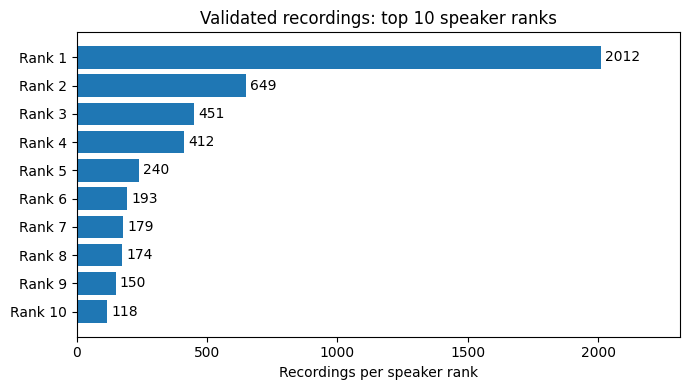

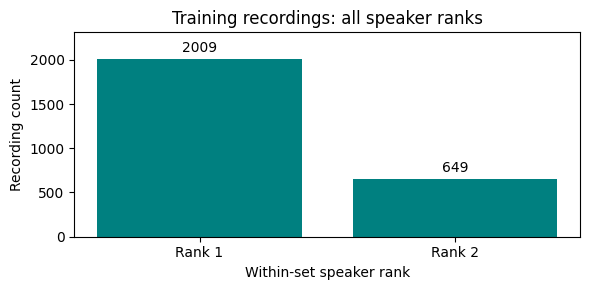

In [6]:
concentration_table = '| Collection | Speaker IDs | Largest speaker share |\n|---|---:|---:|\n'
for name in ['validated.tsv', *split_names]:
    info = metadata[name]
    share = info['speaker_concentration']['largest_speaker_fraction_of_all_rows']
    concentration_table += f"| {name} | {info['unique_nonempty']['client_id']} | {share:.1%} |\n"
display(Markdown(concentration_table))

validated_counts = metadata['validated.tsv']['speaker_concentration']['clip_counts_descending']
top_counts = validated_counts[:10]
ranks = [f'Rank {i + 1}' for i in range(len(top_counts))]

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.barh(ranks, top_counts, color='tab:blue')
ax.bar_label(bars, padding=3)
ax.invert_yaxis()  # Put the largest contributor first.
ax.set(title='Validated recordings: top 10 speaker ranks', xlabel='Recordings per speaker rank')
ax.set_xlim(0, max(top_counts) * 1.15)
fig.tight_layout()
plt.show()
plt.close(fig)

train_counts = metadata['train.tsv']['speaker_concentration']['clip_counts_descending']
train_ranks = [f'Rank {i + 1}' for i in range(len(train_counts))]

fig, ax = plt.subplots(figsize=(6, 3))
bars = ax.bar(train_ranks, train_counts, color='teal')
ax.bar_label(bars, padding=3)
ax.set(title='Training recordings: all speaker ranks', xlabel='Within-set speaker rank', ylabel='Recording count')
ax.set_ylim(0, max(train_counts) * 1.15)
fig.tight_layout()
plt.show()
plt.close(fig)

## Duration distribution from metadata

The audit records the hash and row count of `clip_durations.tsv` but does not compute duration statistics. We therefore reuse its `read_tsv()` parser for this small additional exploration: check clip-key uniqueness, positive finite durations, and validated-path coverage, then convert milliseconds to seconds. Hash checks before and after reading bind these calculations to the audited bytes.

**Measured:** show all available duration records and the validated subset separately. The distribution uses fixed one-second bins for validated recordings. **Interpretation:** these values help plan later length coverage and computational cost. Metadata duration is not a measurement of intelligibility, silence, pronunciation, recording quality, or model performance.

| Metadata collection | Clips | Hours | Mean (s) | Median (s) | Min-max (s) |
|---|---:|---:|---:|---:|---:|
| All duration records | 6,553 | 9.263 | 5.089 | 4.968 | 1.548-13.608 |
| Validated recordings | 6,374 | 8.988 | 5.077 | 4.968 | 1.548-13.356 |


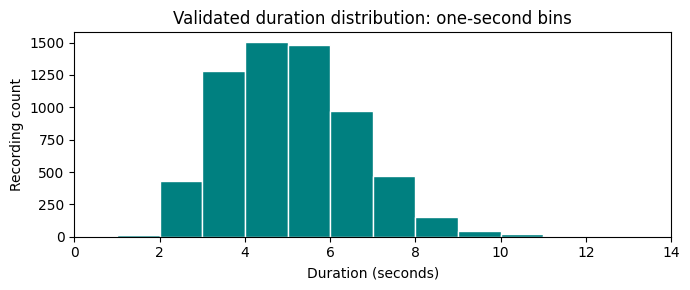

In [7]:
duration_path = DATASET_ROOT / 'clip_durations.tsv'
assert sha256(duration_path) == metadata['clip_durations.tsv']['sha256']
_, duration_rows = read_tsv(duration_path)
durations = {row['clip']: float(row['duration[ms]']) / 1000 for row in duration_rows}
assert len(durations) == len(duration_rows), 'Duplicate duration clip keys.'
assert all(math.isfinite(seconds) and seconds > 0 for seconds in durations.values())
assert manifest_paths['validated.tsv'] <= durations.keys(), 'Missing validated durations.'
assert sha256(duration_path) == metadata['clip_durations.tsv']['sha256']
validated_seconds = [durations[p] for p in sorted(manifest_paths['validated.tsv'])]
all_seconds = list(durations.values())
duration_table = '| Metadata collection | Clips | Hours | Mean (s) | Median (s) | Min-max (s) |\n|---|---:|---:|---:|---:|---:|\n'
for label, seconds in [('All duration records', all_seconds), ('Validated recordings', validated_seconds)]:
    duration_table += (f'| {label} | {len(seconds):,} | {sum(seconds)/3600:.3f} | '
                       f'{statistics.mean(seconds):.3f} | {statistics.median(seconds):.3f} | '
                       f'{min(seconds):.3f}-{max(seconds):.3f} |\n')
display(Markdown(duration_table))

# Fixed one-second bins cover every validated duration, starting at zero.
bin_edges = range(math.floor(max(validated_seconds)) + 2)
fig, ax = plt.subplots(figsize=(7, 3))
counts, edges, bars = ax.hist(validated_seconds, bins=bin_edges, color='teal', edgecolor='white')
assert int(sum(counts)) == len(validated_seconds), 'Histogram omitted recordings.'
ax.set(title='Validated duration distribution: one-second bins', xlabel='Duration (seconds)', ylabel='Recording count')
ax.set_xlim(0, bin_edges[-1])
ax.set_ylim(bottom=0)
fig.tight_layout()
plt.show()
plt.close(fig)

## Text overlap and leakage checks

Normalized text overlap counts shared text keys after a consistent normalization rule. For example, case-only or repeated-whitespace differences can match even when the original strings differ; punctuation and Albanian diacritics remain significant.

**Measured:** the audit finds zero exact clip-path, nonempty speaker-ID, and exact-text overlaps between each pair of supplied splits. After Unicode NFC, case folding, and whitespace collapsing, there are four shared text keys between train/dev, two between train/test, and one between dev/test. These are pairwise unique-key counts, not a count of globally distinct leaked recordings. No text normalization is written back to the data.

**Interpretation:** exact-text independence alone is insufficient to claim full leakage safety. These comparisons miss punctuation variants, paraphrases, related prompts, duplicate waveforms and possible identity links across different IDs. For the thesis, later real/synthetic versions of a text should be considered together when designing evaluation; that is a recommendation, not an implemented split.

In [8]:
overlap_table = '| Pair | Exact paths | Speaker IDs | Exact texts | Normalized texts |\n|---|---:|---:|---:|---:|\n'
for result in current_audit['split_overlaps']:
    exact = result['shared_unique']
    pair = ' / '.join(n.removesuffix('.tsv') for n in result['pair'])
    overlap_table += (f"| {pair} | {exact['path']} | {exact['client_id']} | "
                      f"{exact['sentence']} | {result['shared_normalized_texts']} |\n")
display(Markdown(overlap_table))
assert [r['shared_normalized_texts'] for r in current_audit['split_overlaps']] == [4, 2, 1]

| Pair | Exact paths | Speaker IDs | Exact texts | Normalized texts |
|---|---:|---:|---:|---:|
| train / dev | 0 | 0 | 0 | 4 |
| train / test | 0 | 0 | 0 | 2 |
| dev / test | 0 | 0 | 0 | 1 |


## Limitations and thesis relevance

This is a descriptive metadata exploration, not a real/fake classification experiment. No synthetic class exists in this analysis, so no classifier accuracy, fairness, or generalization claim follows from it.

- Metadata-only analysis cannot establish audio quality, decoding integrity, sample rate, channel count, waveform duplication, or whether a recording is genuinely human.
- Age, gender and accent fields are self-declared and incomplete. Speaker IDs are not verified identities. The speaker charts measure recording contribution, not demographic representativeness.
- The earlier inspection identified source/domain imbalance, including legal text. This notebook does not recompute that source join; the present charts alone cannot establish broad Albanian language, dialect or topic coverage.
- The hash comparison anchors this run to a local snapshot, not an independently authenticated release. It cannot prove historical file identity or unmeasured audio properties. The additional duration checks do not extend the reference JSON's original scope.
- Snapshot assertions intentionally stop on changed counts or overlaps; future releases need an explicitly reviewed new reference rather than quietly accepting new inputs.

**Relevance to the thesis:** these measured coverage and overlap findings motivate later decisions about speaker diversity, text-source coverage, duration coverage and grouped evaluation. They do not decide those policies or select pilot sentences. The audit module remains the reusable source of parsing and overlap logic; this notebook supplies explanation and presentation.

**Review boundary:** raw data, the audit module/tests/JSON, and private notes are preserved. No split creation, model download, audio generation, model training, commit or push is part of this notebook.

## Shpërndarja e gjatësisë së teksteve

**Metoda:** lexojmë `validated.tsv` me `read_tsv()` dhe normalizojmë fushën `sentence` me `normalized_text()` nga moduli i auditimit: Unicode NFC, `casefold` dhe bashkim i whitespace. Pikësimi, **ë** dhe **ç** ruhen. Çdo tekst unik pas normalizimit kontribuon vetëm një herë, pavarësisht numrit të regjistrimeve audio.

Gjatësia llogaritet me `len(text.split())`: numri i njësive të ndara me whitespace. Kjo është **gjatësi teksti**, jo kohëzgjatje audioje apo tokenizim gjuhësor; pikësimi i veçuar me whitespace gjithashtu numërohet si njësi. Raportojmë si rreshtat bosh pas normalizimit, ashtu edhe tekstet unike bosh. Statistikat, tabela dhe grafiku përfshijnë vetëm tekstet unike jo të zbrazëta.

**Percentilet:** `statistics.quantiles(lengths, n=4, method="inclusive")` llogarit P25/P75 me interpolim linear. Në listën e renditur me indekse nga zero, pozicioni është `(n - 1) * p`, ku `p` është 0.25 ose 0.75; interpolohen dy vlerat fqinje kur pozicioni nuk është i plotë. Prandaj percentilet dhe mesatarja mund të jenë jo të plota, edhe pse gjatësitë janë numra të plotë.

**Interpretimi:** kjo përmbledhje përshkruan mbulimin e gjatësive të teksteve në të dhënat aktuale. Nuk vendos pragje, kuota, përzgjedhje të 50 fjalive apo ndarje të reja. Nuk shfaqen fjali individuale ose identifikues folësish.

In [9]:
from collections import Counter
from scripts.audit_common_voice import normalized_text

validated_path = DATASET_ROOT / 'validated.tsv'
assert sha256(validated_path) == metadata['validated.tsv']['sha256']
_, validated_rows = read_tsv(validated_path)
texts = [normalized_text(row['sentence']) for row in validated_rows]
unique_texts = set(texts)
empty_rows = texts.count('')
empty_unique_texts = int('' in unique_texts)
lengths = sorted(len(text.split()) for text in unique_texts if text)
assert len(lengths) == len(unique_texts) - empty_unique_texts
assert len(lengths) >= 2, 'Duhen të paktën dy tekste jo të zbrazëta.'

print('Tekste unike pas normalizimit (përfshirë bosh):', len(unique_texts))
print('Rreshta me tekst bosh pas normalizimit:', empty_rows)
print('Tekste unike bosh:', empty_unique_texts)
print('Tekste unike jo të zbrazëta:', len(lengths))
q25, q50, q75 = statistics.quantiles(lengths, n=4, method='inclusive')
summary = {
    'Minimumi': min(lengths),
    'Mesatarja': statistics.mean(lengths),
    'Mediana': statistics.median(lengths),
    'Maksimumi': max(lengths),
    'P25': q25,
    'P75': q75,
}
summary_table = '| Statistika | Gjatësia (njësi me whitespace) |\n|---|---:|\n'
for label, value in summary.items():
    summary_table += f'| {label} | {value:.3f} |\n'
display(Markdown(summary_table))

length_frequencies = Counter(lengths)
assert sum(length_frequencies.values()) == len(lengths)
frequency_table = '| Gjatësia | Numri i teksteve unike jo bosh |\n|---:|---:|\n'
for length, count in sorted(length_frequencies.items()):
    frequency_table += f'| {length} | {count} |\n'
display(Markdown(frequency_table))

Tekste unike pas normalizimit (përfshirë bosh): 6355
Rreshta me tekst bosh pas normalizimit: 0
Tekste unike bosh: 0
Tekste unike jo të zbrazëta: 6355


| Statistika | Gjatësia (njësi me whitespace) |
|---|---:|
| Minimumi | 1.000 |
| Mesatarja | 8.456 |
| Mediana | 9.000 |
| Maksimumi | 14.000 |
| P25 | 6.000 |
| P75 | 11.000 |


| Gjatësia | Numri i teksteve unike jo bosh |
|---:|---:|
| 1 | 213 |
| 2 | 88 |
| 3 | 194 |
| 4 | 484 |
| 5 | 603 |
| 6 | 496 |
| 7 | 568 |
| 8 | 516 |
| 9 | 500 |
| 10 | 527 |
| 11 | 615 |
| 12 | 488 |
| 13 | 540 |
| 14 | 523 |


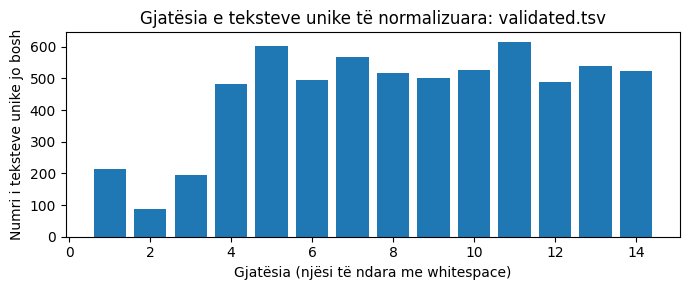

In [10]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(list(length_frequencies), list(length_frequencies.values()), color='tab:blue')
ax.set(
    title='Gjatësia e teksteve unike të normalizuara: validated.tsv',
    xlabel='Gjatësia (njësi të ndara me whitespace)',
    ylabel='Numri i teksteve unike jo bosh',
)
ax.set_ylim(bottom=0)
fig.tight_layout()
plt.show()
plt.close(fig)

In [11]:
# Final guard: all audited TSV bytes still match after exploration.
for name, info in metadata.items():
    assert sha256(DATASET_ROOT / name) == info['sha256'], f'Input changed: {name}'
print('All audited metadata hashes still match. Exploration complete; stop for review.')

All audited metadata hashes still match. Exploration complete; stop for review.
